<a href="https://colab.research.google.com/github/421110016-a11y/Sistemas_inteligente-/blob/main/Fashion_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Proyecto: Clasificación de imágenes con redes neuronales artificiales

### Pregunta de investigación

¿Cómo influye la arquitectura de una red neuronal artificial en la precisión para clasificar imágenes de prendas de vestir?

### Objetivo general

Desarrollar y comparar diferentes configuraciones de redes neuronales artificiales utilizando Fashion-MNIST, con la finalidad de identificar qué arquitectura presenta mayor accuracy en la clasificación de imágenes.

### Metodología

Se utilizarán imágenes en escala de grises de 28 × 28 píxeles. Cada imagen será transformada mediante una capa Flatten para que pueda ser procesada por las capas densas de una red neuronal.

Se entrenarán al menos tres configuraciones diferentes, modificando la cantidad de capas ocultas y neuronas. Posteriormente, se compararán sus resultados utilizando accuracy.

También se realizará una visualización bidimensional de las representaciones aprendidas por una red neuronal, para observar cómo se distribuyen las diferentes categorías de prendas.

In [13]:
# =====================================================
#  — LIBRERÍAS
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)


print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [5]:
# =====================================================
#  — CARGA DE FASHION-MNIST
# =====================================================

train_raw, val_raw, test_raw = tfds.load(
    "fashion_mnist",
    split=[
        "train[:90%]",
        "train[90%:]",
        "test"
    ],
    as_supervised=True,
    shuffle_files=True
)

print("Entrenamiento:", train_raw.cardinality().numpy())
print("Validación:", val_raw.cardinality().numpy())
print("Prueba:", test_raw.cardinality().numpy())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-train.tfrecord-[0-9][0…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/fashion_mnist/incomplete.HBRPOI_3.0.1/fashion_mnist-test.tfrecord-[0-9][0-…

Dataset fashion_mnist downloaded and prepared to /root/tensorflow_datasets/fashion_mnist/3.0.1. Subsequent calls will reuse this data.
Entrenamiento: 54000
Validación: 6000
Prueba: 10000


In [4]:
%pip install -q importlib_resources

### Carga del conjunto de datos Fashion-MNIST

Se cargó correctamente el conjunto de datos Fashion-MNIST mediante la biblioteca TensorFlow Datasets.

El dataset contiene 70,000 imágenes de prendas de vestir, distribuidas en 54,000 observaciones de entrenamiento, 6,000 de validación y 10,000 de prueba.

Esta división permitirá utilizar los datos de entrenamiento para ajustar los parámetros de nuestra red neuronal, los datos de validación para comparar las diferentes arquitecturas y los datos de prueba para evaluar el modelo seleccionado.

La carga se realizó correctamente y podemos continuar con la preparación de las imágenes.

In [6]:
# =====================================================
#  — NORMALIZACIÓN DE IMÁGENES
# =====================================================

def normalizar(imagen, etiqueta):
    imagen = tf.cast(imagen, tf.float32) / 255.0
    return imagen, etiqueta

AUTOTUNE = tf.data.AUTOTUNE

# Entrenamiento
train_ds = (
    train_raw
    .map(normalizar, num_parallel_calls=AUTOTUNE)
    .shuffle(10000, seed=42)
    .batch(32)
    .prefetch(AUTOTUNE)
)

# Validación
val_ds = (
    val_raw
    .map(normalizar, num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

# Prueba
test_ds = (
    test_raw
    .map(normalizar, num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

# Verificar un lote
for imagenes, etiquetas in train_ds.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Valor mínimo:", tf.reduce_min(imagenes).numpy())
    print("Valor máximo:", tf.reduce_max(imagenes).numpy())

Dimensiones del lote: (32, 28, 28, 1)
Dimensiones de etiquetas: (32,)
Valor mínimo: 0.0
Valor máximo: 1.0


### Normalización de las imágenes

Se realizó la normalización de las imágenes de Fashion-MNIST, transformando las intensidades de los píxeles del intervalo original de 0 a 255 al intervalo de 0 a 1.

Al verificar los resultados, obtuvimos lotes de 32 imágenes, cada una con dimensiones de 28 × 28 píxeles y un canal de escala de grises.

También comprobamos que los valores mínimo y máximo de intensidad son 0.0 y 1.0, respectivamente.

Esta transformación permitirá trabajar con valores numéricos en una escala uniforme, facilitando el entrenamiento de nuestra red neuronal.

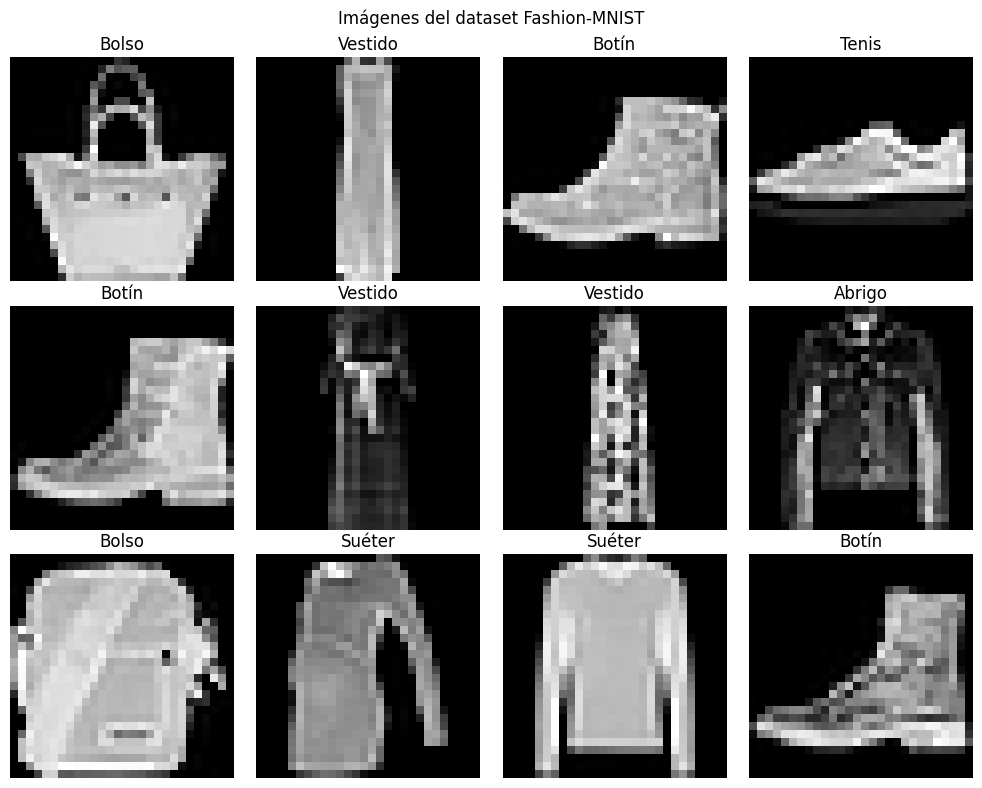

In [7]:
# =====================================================
# — VISUALIZACIÓN DE FASHION-MNIST
# =====================================================

clases = [
    "Camiseta", "Pantalón", "Suéter",
    "Vestido", "Abrigo", "Sandalia",
    "Camisa", "Tenis", "Bolso", "Botín"
]

plt.figure(figsize=(10, 8))

for imagenes, etiquetas in train_ds.take(1):

    for i in range(12):
        plt.subplot(3, 4, i + 1)

        plt.imshow(
            tf.squeeze(imagenes[i]),
            cmap="gray"
        )

        plt.title(clases[int(etiquetas[i])])
        plt.axis("off")

plt.suptitle("Imágenes del dataset Fashion-MNIST")
plt.tight_layout()
plt.show()

### Visualización de imágenes de Fashion-MNIST

Se visualizaron 12 imágenes del conjunto de entrenamiento para conocer las características del dataset.

Observamos diferentes prendas de vestir y accesorios, como bolsos, vestidos, botines, tenis, abrigos y suéteres.

Todas las imágenes están representadas en escala de grises y tienen una resolución de 28 × 28 píxeles.

También observamos que algunas categorías presentan características visuales similares, lo que podría dificultar su clasificación.

Esta exploración nos permite comprender el tipo de información que utilizará nuestra red neuronal para aprender a identificar las diferentes categorías.

In [10]:
# =====================================================
#  — COMPROBACIÓN DE FLATTEN
# =====================================================
# Tomar un lote de imágenes
for imagenes, etiquetas in train_ds.take(1):

    print("Dimensión original:")
    print(imagenes.shape)

    # Aplicar Flatten
    capa_flatten = layers.Flatten()

    imagenes_planas = capa_flatten(imagenes)

    print("\nDimensión después de Flatten:")
    print(imagenes_planas.shape)

    print("\nNúmero de valores por imagen:")
    print(imagenes_planas.shape[1])

Dimensión original:
(32, 28, 28, 1)

Dimensión después de Flatten:
(32, 784)

Número de valores por imagen:
784


In [9]:
modelo = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

In [11]:
# =====================================================
#  — CONSTRUCCIÓN DEL MODELO A
# =====================================================

# Reproducibilidad
tf.keras.utils.set_random_seed(42)

# Construcción del modelo
modelo_a = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Transformar la imagen en 784 valores
    layers.Flatten(),

    # Capa oculta
    layers.Dense(64, activation="relu"),

    # Capa de salida
    layers.Dense(10, activation="softmax")
])

# Compilación
modelo_a.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Visualizar arquitectura
modelo_a.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,890 (198.79 KB)

 Trainable params: 50,890 (198.79 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# =====================================================
#  — ENTRENAMIENTO DEL MODELO A
# =====================================================

# Configurar Early Stopping
early_stopping_a = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Entrenar la red neuronal
historial_a = modelo_a.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_a],
    verbose=1
)

print("\nENTRENAMIENTO FINALIZADO")

print(
    "Épocas ejecutadas:",
    len(historial_a.history["loss"])
)

print(
    "Mejor accuracy de validación:",
    round(max(historial_a.history["val_accuracy"]), 4)
)

print(
    "Menor pérdida de validación:",
    round(min(historial_a.history["val_loss"]), 4)
)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 15s 7ms/step - accuracy: 0.8191 - loss: 0.5255 - val_accuracy: 0.8560 - val_loss: 0.4103
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8596 - loss: 0.3988 - val_accuracy: 0.8473 - val_loss: 0.4114
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8692 - loss: 0.3623 - val_accuracy: 0.8765 - val_loss: 0.3450
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8787 - loss: 0.3370 - val_accuracy: 0.8758 - val_loss: 0.3422
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8851 - loss: 0.3190 - val_accuracy: 0.8742 - val_loss: 0.3358
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8885 - loss: 0.3046 - val_accuracy: 0.8782 - val_loss: 0.3241
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8918 - loss: 0.2921 - val_accuracy: 0.8817 - val_loss: 0.3158
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8976 - loss: 0.2825 

In [16]:
# =====================================================
# — CONSTRUCCIÓN DEL MODELO B
# =====================================================

tf.keras.utils.set_random_seed(42)

modelo_b = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Transformar la imagen en 784 valores
    layers.Flatten(),

    # Primera capa oculta
    layers.Dense(128, activation="relu"),

    # Segunda capa oculta
    layers.Dense(64, activation="relu"),

    # Capa de salida
    layers.Dense(10, activation="softmax")
])

modelo_b.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_b.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
# =====================================================
#  — ENTRENAMIENTO DEL MODELO B
# =====================================================

early_stopping_b = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

historial_b = modelo_b.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_b],
    verbose=1
)

print("\nENTRENAMIENTO FINALIZADO")

print(
    "Épocas ejecutadas:",
    len(historial_b.history["loss"])
)

print(
    "Mejor accuracy de validación:",
    round(max(historial_b.history["val_accuracy"]), 4)
)

print(
    "Menor pérdida de validación:",
    round(min(historial_b.history["val_loss"]), 4)
)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8211 - loss: 0.5028 - val_accuracy: 0.8550 - val_loss: 0.3968
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8619 - loss: 0.3749 - val_accuracy: 0.8712 - val_loss: 0.3541
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 18s 6ms/step - accuracy: 0.8744 - loss: 0.3398 - val_accuracy: 0.8785 - val_loss: 0.3286
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.8844 - loss: 0.3130 - val_accuracy: 0.8782 - val_loss: 0.3322
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8916 - loss: 0.2941 - val_accuracy: 0.8792 - val_loss: 0.3237
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8941 - loss: 0.2801 - val_accuracy: 0.8828 - val_loss: 0.3168
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8986 - loss: 0.2687 - val_accuracy: 0.8900 - val_loss: 0.3077
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9028 - loss: 0

## Modelo B: Red neuronal con dos capas ocultas

### Objetivo

Evaluar si una arquitectura con dos capas ocultas mejora el desempeño de clasificación respecto al Modelo A.

### Arquitectura

Se construyó una red neuronal con una capa Flatten que transforma cada imagen de 28 × 28 píxeles en un vector de 784 características.

Posteriormente, se incorporaron dos capas ocultas de 128 y 64 neuronas, ambas con activación ReLU.

La capa de salida contiene 10 neuronas con activación Softmax, correspondientes a las diez categorías de Fashion-MNIST.

El modelo tiene 109,386 parámetros entrenables.

### Entrenamiento

Se utilizará el optimizador Adam, con una tasa de aprendizaje de 0.001 y la función de pérdida Sparse Categorical Crossentropy.

El entrenamiento tendrá un máximo de 30 épocas y utilizará Early Stopping para recuperar los pesos correspondientes a la menor pérdida de validación.

Los resultados permitirán comparar el accuracy del Modelo B con el obtenido anteriormente por el Modelo A.

In [19]:
# =====================================================
#  — MODELO C
# =====================================================

tf.keras.utils.set_random_seed(42)

# 1. Construir arquitectura
modelo_c = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

# 2. Compilar
modelo_c.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# 3. Revisar arquitectura
modelo_c.summary()

# 4. Configurar Early Stopping
early_stopping_c = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# 5. Entrenar
historial_c = modelo_c.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_c],
    verbose=1
)

# 6. Resultados
print("\nENTRENAMIENTO DEL MODELO C FINALIZADO")

print(
    "Épocas ejecutadas:",
    len(historial_c.history["loss"])
)

print(
    "Mejor accuracy de validación:",
    round(max(historial_c.history["val_accuracy"]), 4)
)

print(
    "Menor pérdida de validación:",
    round(min(historial_c.history["val_loss"]), 4)
)

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.8201 - loss: 0.5003 - val_accuracy: 0.8465 - val_loss: 0.3953
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8637 - loss: 0.3709 - val_accuracy: 0.8597 - val_loss: 0.3802
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8782 - loss: 0.3330 - val_accuracy: 0.8710 - val_loss: 0.3536
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8832 - loss: 0.3134 - val_accuracy: 0.8883 - val_loss: 0.3068
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8905 - loss: 0.2948 - val_accuracy: 0.8923 - val_loss: 0.2997
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8950 - loss: 0.2783 - val_accuracy: 0.8895 - val_loss: 0.3001
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.8997 - loss: 0.2678 - val_accuracy: 0.8877 - val_loss: 0.3131
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 14s 8ms/step - accuracy: 0.9044 - loss: 0

### Resultados del entrenamiento del Modelo C

Se entrenó una tercera arquitectura de red neuronal con tres capas ocultas de 256, 128 y 64 neuronas, utilizando ReLU como función de activación y Softmax en la capa de salida.

El modelo completó 15 épocas de entrenamiento y alcanzó un accuracy máximo de validación de 89.88%, con una pérdida mínima de 0.2920.

Al compararlo con el Modelo B, observamos una mejora de 0.21 puntos porcentuales en el mayor accuracy registrado. Sin embargo, el Modelo C tiene una arquitectura más compleja y requiere una mayor cantidad de parámetros.

Estos resultados muestran que aumentar las capas y las neuronas puede producir pequeñas mejoras en accuracy, aunque no necesariamente mejora todas las métricas.

Por lo tanto, es necesario comparar los tres modelos bajo las mismas condiciones antes de seleccionar la arquitectura final.

In [20]:
# =====================================================
#  — COMPARACIÓN DE LOS TRES MODELOS
# =====================================================

import pandas as pd

modelos = {
    "A - Simple": (modelo_a, historial_a),
    "B - Intermedio": (modelo_b, historial_b),
    "C - Profundo": (modelo_c, historial_c)
}

resultados = []

for nombre, (modelo, historial) in modelos.items():

    # Evaluar pesos restaurados
    loss, accuracy = modelo.evaluate(
        val_ds,
        verbose=0
    )

    resultados.append({
        "Modelo": nombre,
        "Parametros": modelo.count_params(),
        "Epocas": len(historial.history["loss"]),
        "Accuracy_Validacion": accuracy,
        "Loss_Validacion": loss
    })

df_resultados = pd.DataFrame(resultados)

display(
    df_resultados.sort_values(
        "Accuracy_Validacion",
        ascending=False
    ).round(4)
)

,Modelo,Parametros,Epocas,Accuracy_Validacion,Loss_Validacion
2,C - Profundo,242762,15,0.8968,0.2920
0,A - Simple,50890,16,0.8903,0.2987
1,B - Intermedio,109386,13,0.8898,0.2907


In [21]:
# =====================================================
# — COMPARACIÓN FINAL DE ARQUITECTURAS
# =====================================================

# Modelos entrenados
modelos = {
    "A - Simple": (modelo_a, historial_a),
    "B - Intermedio": (modelo_b, historial_b),
    "C - Profundo": (modelo_c, historial_c)
}

resultados = []

# Evaluar cada modelo
for nombre, (modelo, historial) in modelos.items():

    loss, accuracy = modelo.evaluate(
        val_ds,
        verbose=0
    )

    resultados.append({
        "Modelo": nombre,
        "Parametros": modelo.count_params(),
        "Epocas": len(historial.history["loss"]),
        "Accuracy": accuracy,
        "Loss": loss
    })

# Crear tabla comparativa
df_resultados = pd.DataFrame(resultados)

# Ordenar de mayor a menor accuracy
df_resultados = df_resultados.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print("=" * 60)
print("COMPARACIÓN FINAL DE REDES NEURONALES")
print("=" * 60)

display(df_resultados.round(4))

# Identificar modelo con mayor accuracy
mejor_modelo = df_resultados.iloc[0]

print("\nMODELO CON MAYOR ACCURACY")
print("Modelo:", mejor_modelo["Modelo"])
print(f"Accuracy: {mejor_modelo['Accuracy']:.2%}")

COMPARACIÓN FINAL DE REDES NEURONALES


,Modelo,Parametros,Epocas,Accuracy,Loss
0,C - Profundo,242762,15,0.8968,0.2920
1,A - Simple,50890,16,0.8903,0.2987
2,B - Intermedio,109386,13,0.8898,0.2907



MODELO CON MAYOR ACCURACY
Modelo: C - Profundo
Accuracy: 89.68%


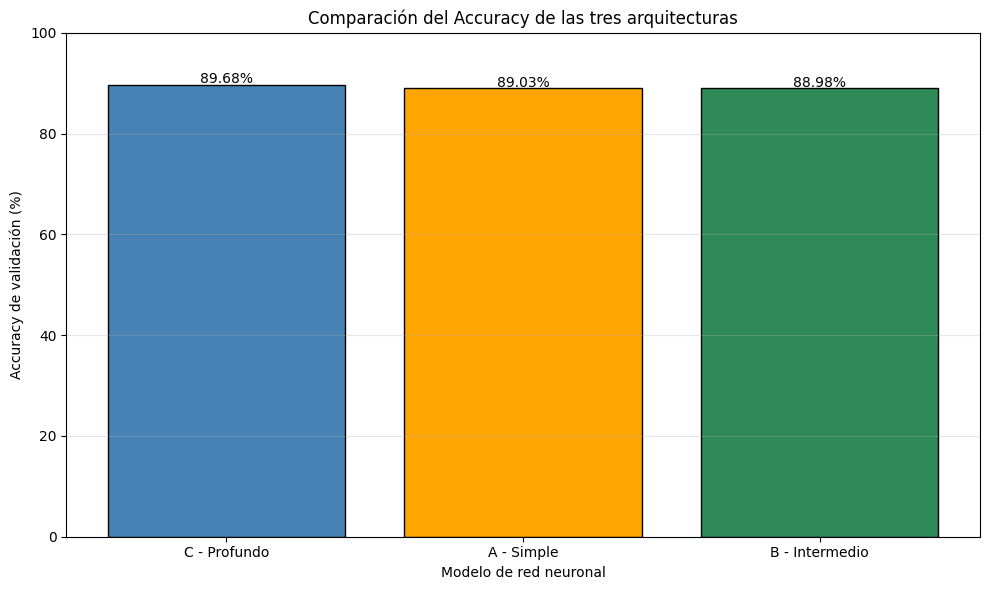

In [22]:
# =====================================================
# GRÁFICA — COMPARACIÓN DE ACCURACY
# =====================================================

plt.figure(figsize=(10, 6))

accuracy_pct = df_resultados["Accuracy"] * 100

barras = plt.bar(
    df_resultados["Modelo"],
    accuracy_pct,
    color=["steelblue", "orange", "seagreen"],
    edgecolor="black"
)

# Mostrar porcentajes
for barra, valor in zip(barras, accuracy_pct):
    plt.text(
        barra.get_x() + barra.get_width()/2,
        barra.get_height() + 0.3,
        f"{valor:.2f}%",
        ha="center"
    )

plt.title("Comparación del Accuracy de las tres arquitecturas")
plt.xlabel("Modelo de red neuronal")
plt.ylabel("Accuracy de validación (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Comparación de las tres arquitecturas de redes neuronales

Se compararon tres configuraciones de redes neuronales utilizando el conjunto de validación de Fashion-MNIST y la métrica accuracy.

El Modelo C obtuvo el mejor resultado, con un accuracy de 89.68%, seguido del Modelo A con 89.03% y del Modelo B con 88.98%.

Aunque el Modelo C presentó la mayor exactitud, la diferencia entre las tres arquitecturas fue relativamente pequeña. Esto indica que aumentar la cantidad de capas y neuronas no siempre genera una mejora considerable en la clasificación.

También observamos que el Modelo A, a pesar de utilizar una arquitectura más sencilla y menos parámetros, consiguió resultados cercanos a los del modelo más profundo.

Por lo tanto, si buscamos maximizar el accuracy de validación, seleccionamos el Modelo C. Sin embargo, si consideramos la simplicidad y la cantidad de parámetros, el Modelo A también representa una alternativa adecuada.

In [23]:
# =====================================================
#  — RED NEURONAL CON REPRESENTACIÓN 2D
# =====================================================

tf.keras.utils.set_random_seed(42)

# Crear modelo con capa de dos neuronas
entrada = keras.Input(shape=(28, 28, 1))

x = layers.Flatten()(entrada)
x = layers.Dense(128, activation="relu")(x)

# Capa que genera las dos coordenadas
representacion_2d = layers.Dense(
    2,
    activation="linear",
    name="representacion_2d"
)(x)

salida = layers.Dense(
    10,
    activation="softmax"
)(representacion_2d)

modelo_2d = keras.Model(
    inputs=entrada,
    outputs=salida
)

modelo_2d.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

modelo_2d.summary()

Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ representacion_2d (Dense)       │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,768 (393.62 KB)

 Trainable params: 100,768 (393.62 KB)

 Non-trainable params: 0 (0.00 B)

### Construcción de una red neuronal para visualización 2D

Se construyó una red neuronal adicional para obtener una representación bidimensional de las imágenes de Fashion-MNIST.

La arquitectura incluye una capa Flatten que transforma las imágenes en 784 características, una capa oculta de 128 neuronas con activación ReLU y una capa intermedia de dos neuronas.

Esta última capa permitirá representar cada imagen mediante dos coordenadas numéricas.

Finalmente, se incorporó una capa de salida de 10 neuronas con activación Softmax para realizar la clasificación.

El modelo contiene 100,768 parámetros entrenables.

El objetivo es analizar cómo se distribuyen las diferentes categorías de prendas en un espacio de dos dimensiones.

In [24]:
# =====================================================
#  — ENTRENAMIENTO DE LA RED 2D
# =====================================================



early_stopping_2d = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

historial_2d = modelo_2d.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stopping_2d],
    verbose=1
)

# Evaluación con los pesos restaurados
loss_2d, accuracy_2d = modelo_2d.evaluate(
    val_ds,
    verbose=0
)

print("\nENTRENAMIENTO 2D FINALIZADO")
print("Épocas ejecutadas:", len(historial_2d.history["loss"]))
print(f"Accuracy de validación: {accuracy_2d:.2%}")
print(f"Pérdida de validación: {loss_2d:.4f}")

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.6328 - loss: 1.1062 - val_accuracy: 0.7823 - val_loss: 0.7787
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8060 - loss: 0.6735 - val_accuracy: 0.8143 - val_loss: 0.6268
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 22s 7ms/step - accuracy: 0.8334 - loss: 0.5583 - val_accuracy: 0.8272 - val_loss: 0.5532
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8477 - loss: 0.5023 - val_accuracy: 0.8455 - val_loss: 0.5045
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8548 - loss: 0.4671 - val_accuracy: 0.8512 - val_loss: 0.4953
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.8625 - loss: 0.4397 - val_accuracy: 0.8498 - val_loss: 0.4904
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8677 - loss: 0.4217 - val_accuracy: 0.8565 - val_loss: 0.4663
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8713 - loss: 0

In [25]:
# =====================================================
#  — EXTRACCIÓN DE CARACTERÍSTICAS 2D
# =====================================================

# Crear modelo que termina en la capa de dos neuronas
extractor_2d = keras.Model(
    inputs=modelo_2d.input,
    outputs=modelo_2d.get_layer(
        "representacion_2d"
    ).output
)

# Extraer imágenes y etiquetas de validación
imagenes_val = []
etiquetas_val = []

for imagenes, etiquetas in val_ds:
    imagenes_val.append(imagenes.numpy())
    etiquetas_val.append(etiquetas.numpy())

imagenes_val = np.concatenate(imagenes_val)
etiquetas_val = np.concatenate(etiquetas_val)

# Obtener dos coordenadas por imagen
coordenadas_2d = extractor_2d.predict(
    imagenes_val,
    verbose=0
)

print("Imágenes de validación:", imagenes_val.shape)
print("Etiquetas:", etiquetas_val.shape)
print("Coordenadas 2D:", coordenadas_2d.shape)

print("\nPrimeras cinco coordenadas:")
print(coordenadas_2d[:5])

Imágenes de validación: (6000, 28, 28, 1)
Etiquetas: (6000,)
Coordenadas 2D: (6000, 2)

Primeras cinco coordenadas:
[[ 21.32866  -22.962769]
 [  6.997937   5.17581 ]
 [  8.132195 -23.175846]
 [-12.87838  -35.635437]
 [-24.489948 -10.07313 ]]


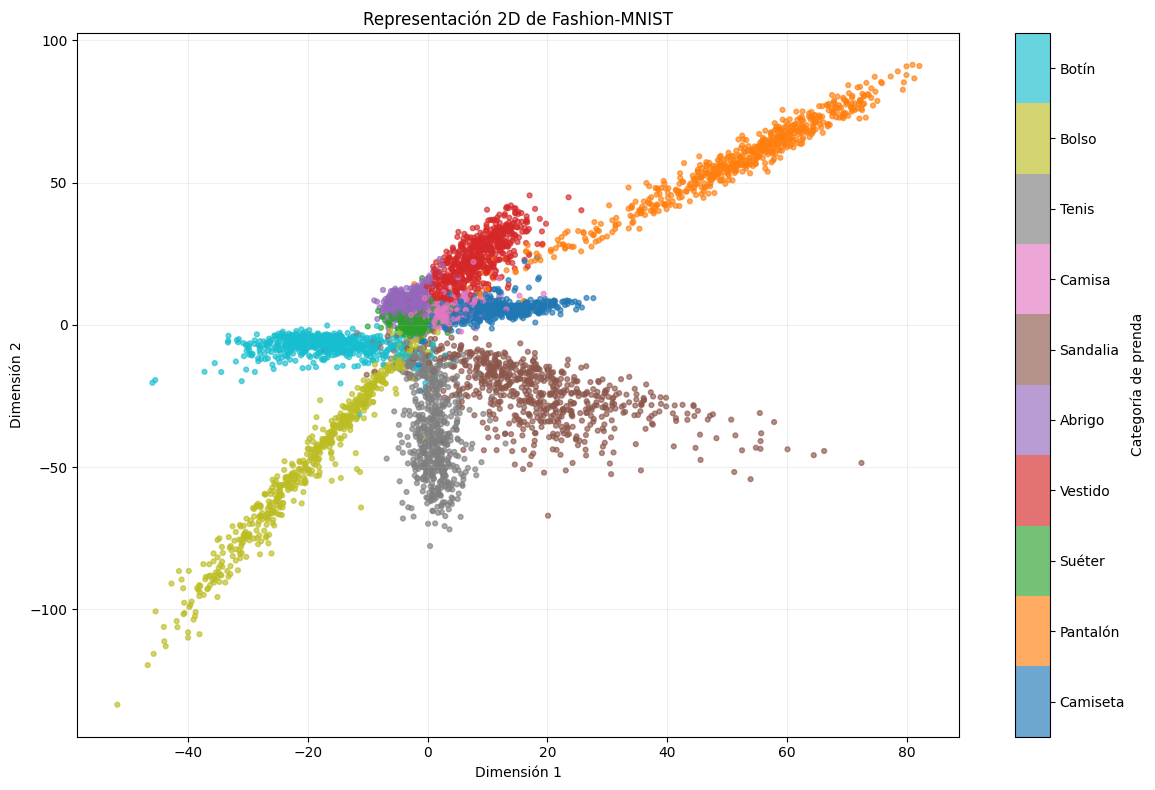

In [26]:
# =====================================================
#  — VISUALIZACIÓN DE FASHION-MNIST EN 2D
# =====================================================


clases = [
    "Camiseta", "Pantalón", "Suéter",
    "Vestido", "Abrigo", "Sandalia",
    "Camisa", "Tenis", "Bolso", "Botín"
]

plt.figure(figsize=(12, 8))

grafica = plt.scatter(
    coordenadas_2d[:, 0],
    coordenadas_2d[:, 1],
    c=etiquetas_val,
    cmap="tab10",
    s=12,
    alpha=0.65,
    vmin=-0.5,
    vmax=9.5
)

barra = plt.colorbar(grafica, ticks=range(10))
barra.ax.set_yticklabels(clases)
barra.set_label("Categoría de prenda")

plt.title(
    "Representación 2D de Fashion-MNIST"
)

plt.xlabel("Dimensión 1")
plt.ylabel("Dimensión 2")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la representación bidimensional de Fashion-MNIST

Se generó una gráfica de dispersión utilizando las 6,000 imágenes del conjunto de validación. Para ello, se extrajeron las dos características aprendidas por la capa intermedia de nuestra red neuronal.

Cada punto representa una imagen y su color identifica la categoría de prenda a la que pertenece.

En los resultados observamos que algunas categorías, como pantalón, bolso, botín y tenis, forman agrupaciones relativamente diferenciadas.

Por otro lado, categorías como camiseta, suéter, abrigo y camisa presentan una mayor superposición en la región central de la gráfica.

Esto indica que la red neuronal consiguió aprender una representación bidimensional que permite distinguir varias categorías, aunque algunas prendas conservan características difíciles de separar en únicamente

In [27]:
# =====================================================
# — EVALUACIÓN FINAL DEL MODELO C
# =====================================================

# Evaluación con las 10,000 imágenes de prueba
loss_test, accuracy_test = modelo_c.evaluate(
    test_ds,
    verbose=1
)

print("=" * 55)
print("EVALUACIÓN FINAL — MODELO C")
print("=" * 55)

print(f"Accuracy de prueba: {accuracy_test:.2%}")
print(f"Pérdida de prueba: {loss_test:.4f}")

print("\nComparación:")
print("Accuracy de validación: 89.68%")
print(f"Accuracy de prueba: {accuracy_test:.2%}")

print(
    "Diferencia (puntos porcentuales):",
    round((accuracy_test - 0.8968) * 100, 2)
)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8818 - loss: 0.3371
EVALUACIÓN FINAL — MODELO C
Accuracy de prueba: 88.18%
Pérdida de prueba: 0.3371

Comparación:
Accuracy de validación: 89.68%
Accuracy de prueba: 88.18%
Diferencia (puntos porcentuales): -1.5


## Evaluación final del Modelo C

Después de comparar tres arquitecturas de redes neuronales, se seleccionó el Modelo C porque obtuvo el mayor accuracy de validación, con un 89.68%.

Posteriormente, se evaluó utilizando las 10,000 imágenes del conjunto de prueba de Fashion-MNIST, que no habían sido utilizadas durante el entrenamiento ni para seleccionar el modelo.

En esta evaluación se obtuvo un accuracy de 88.18% y una pérdida de 0.3371.

Esto significa que el modelo logró clasificar correctamente aproximadamente 88 de cada 100 imágenes de prueba.

Al comparar los resultados de validación y prueba, observamos una disminución de 1.50 puntos porcentuales.

Esta diferencia indica que el rendimiento fue ligeramente menor al evaluar imágenes nuevas, aunque se mantuvo cercano al obtenido durante la validación.

En conclusión, el Modelo C mostró una buena capacidad de clasificación y resultados relativamente consistentes entre los conjuntos de validación y prueba.

También comprobamos que una arquitectura más profunda puede mejorar el accuracy, aunque el aumento de complejidad no necesariamente produce mejoras grandes.

Por último, mediante la representación bidimensional observamos que algunas prendas forman agrupaciones distinguibles, mientras que otras categorías presentan mayor superposición debido a sus similitudes visuales.